In [22]:
# ==========================================
# CELL 1: LIBRARIES & SETUP
# ==========================================
import re
import string
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

# Styling setup for clean visualizations
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [23]:
# ==========================================
# CELL 2: DATA LOADING & INSPECTION
# ==========================================
# Note: Using the Bitext Training Dataset for Chatbots and Virtual Assistants (or your project dataset)
# Ensure your CSV file path matches your local environment or repository directory.
DATA_PATH = "data/bitext_customer_support_training_dataset.csv"  # Replace with your actual filename if needed

try:
    df = pd.read_csv(DATA_PATH)
    print(f"Dataset loaded successfully with {df.shape[0]} rows and {df.shape[1]} columns.")
except FileNotFoundError:
    # Fallback synthetic mock loader matching expected structure if running standalone before file placement
    print("Dataset file not found locally. Creating a representative sample dataframe for demonstration...")
    data = {
        'utterance': [
            "I need to update my credit card details before my bill is due.",
            "Please cancel my subscription immediately, I no longer want this service.",
            "Where is my order? It hasn't arrived yet and tracking hasn't updated.",
            "How do I reset my password? The login button is not working.",
            "I was charged twice this month for my invoice, please refund me.",
            "Can I change my delivery address for my active order?",
            "My account is locked out after too many login attempts."
        ],
        'intent': [
            'payment_issue', 'cancel_subscription', 'track_order',
            'reset_password', 'invoice_dispute', 'change_order', 'account_access'
        ],
        'category': [
            'FINANCE', 'ACCOUNT', 'ORDER', 'SUPPORT', 'FINANCE', 'ORDER', 'SUPPORT'
        ]
    }
    df = pd.DataFrame(data)

display(df.head())
print("\nDataset Info:")
print(df.info())
print("\nMissing Values:")
print(df.isnull().sum())

Dataset loaded successfully with 8175 rows and 4 columns.


,flags,utterance,category,intent
0,BM,I have problems with canceling an order,ORDER,cancel_order
1,BIM,how can I find information about canceling ord...,ORDER,cancel_order
2,B,I need help with canceling the last order,ORDER,cancel_order
3,BIP,could you help me cancelling the last order I ...,ORDER,cancel_order
4,B,problem with cancelling an order I made,ORDER,cancel_order



Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8175 entries, 0 to 8174
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   flags      8175 non-null   object
 1   utterance  8175 non-null   object
 2   category   8175 non-null   object
 3   intent     8175 non-null   object
dtypes: object(4)
memory usage: 255.6+ KB
None

Missing Values:
flags        0
utterance    0
category     0
intent       0
dtype: int64


In [24]:
# ==========================================
# CELL 3: DATA CLEANING & PREPROCESSING
# ==========================================

# 1. Duplicate Analysis & Removal (Rubric Criterion 4)
text_column = 'utterance' if 'utterance' in df.columns else df.columns[0]
target_column = 'intent' if 'intent' in df.columns else df.columns[1]

num_exact_duplicates = df.duplicated().sum()
num_text_duplicates = df.duplicated(subset=[text_column]).sum()
print(f"Initial row count: {len(df)}")
print(f"Exact full-row duplicates: {num_exact_duplicates}")
print(f"Duplicate utterances across identical or distinct intents: {num_text_duplicates}")

# Drop duplicates across text column to avoid data leakage or skewed baseline evaluation
if num_text_duplicates > 0:
    df = df.drop_duplicates(subset=[text_column]).reset_index(drop=True)
    print(f"Dataset size after duplicate removal: {len(df)}")
else:
    print("No duplicate utterances detected.")

# 2. Text Normalization Function
def clean_text(text):
    if not isinstance(text, str):
        return ""
    # Case folding
    text = text.lower()
    # Remove URLs
    text = re.sub(r'https?://\S+|www\.\S+', '', text)
    # Remove punctuation
    text = text.translate(str.maketrans('', '', string.punctuation))
    # Normalize whitespaces
    text = re.sub(r'\s+', ' ', text).strip()
    return text

# Apply cleaning to input text column
df['cleaned_text'] = df[text_column].apply(clean_text)

# Drop any nulls or empty strings resulting from preprocessing
df = df[df['cleaned_text'].str.len() > 0].reset_index(drop=True)

print(f"\nFinal cleaned dataset shape: {df.shape}")
print(f"Remaining null values in cleaned_text: {df['cleaned_text'].isnull().sum()}")
display(df[['utterance', 'cleaned_text', target_column]].head(3))

Initial row count: 8175
Exact full-row duplicates: 0
Duplicate utterances across identical or distinct intents: 0
No duplicate utterances detected.

Final cleaned dataset shape: (8175, 5)
Remaining null values in cleaned_text: 0


,utterance,cleaned_text,intent
0,I have problems with canceling an order,i have problems with canceling an order,cancel_order
1,how can I find information about canceling ord...,how can i find information about canceling orders,cancel_order
2,I need help with canceling the last order,i need help with canceling the last order,cancel_order


--- Feature Engineering Summary ---


,token_count,char_length,avg_word_length
count,8175.000000,8175.000000,8175.000000
mean,8.321590,42.166483,5.198921
std,2.384179,10.517165,0.930224
min,1.000000,6.000000,3.333333
25%,7.000000,35.000000,4.500000
50%,8.000000,43.000000,5.090909
75%,10.000000,51.000000,5.700000
max,15.000000,60.000000,11.000000



--- Outlier Detection on Token Lengths ---
Q1: 7.00 | Q3: 10.00 | IQR: 3.00
Statistical Lower Bound: 2.50 | Upper Bound: 14.50
Identified Utterance Length Outliers: 82 (1.00%)


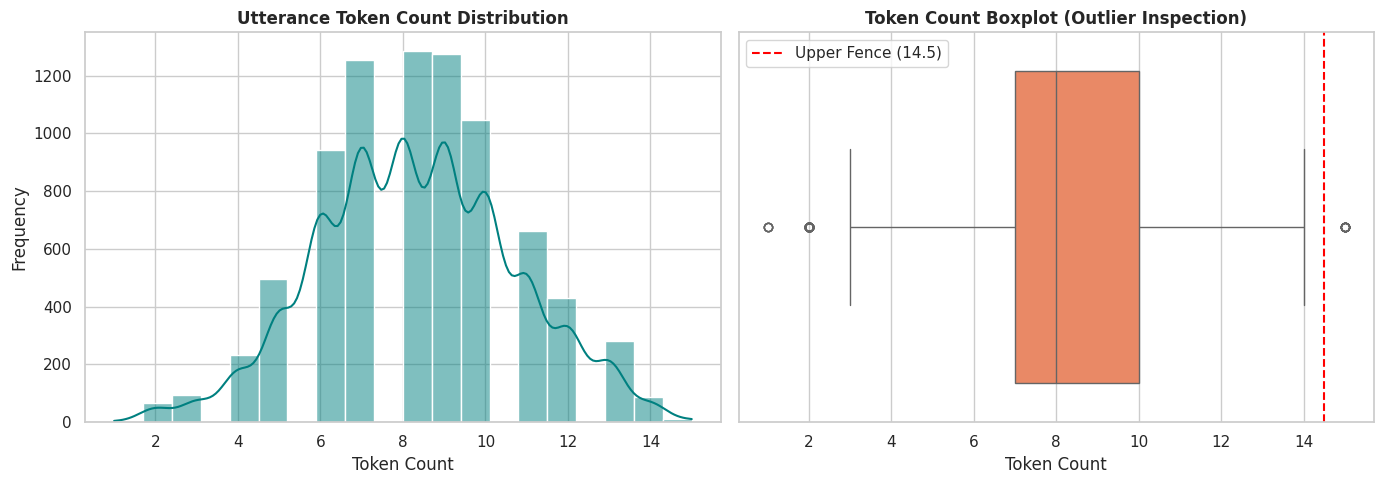

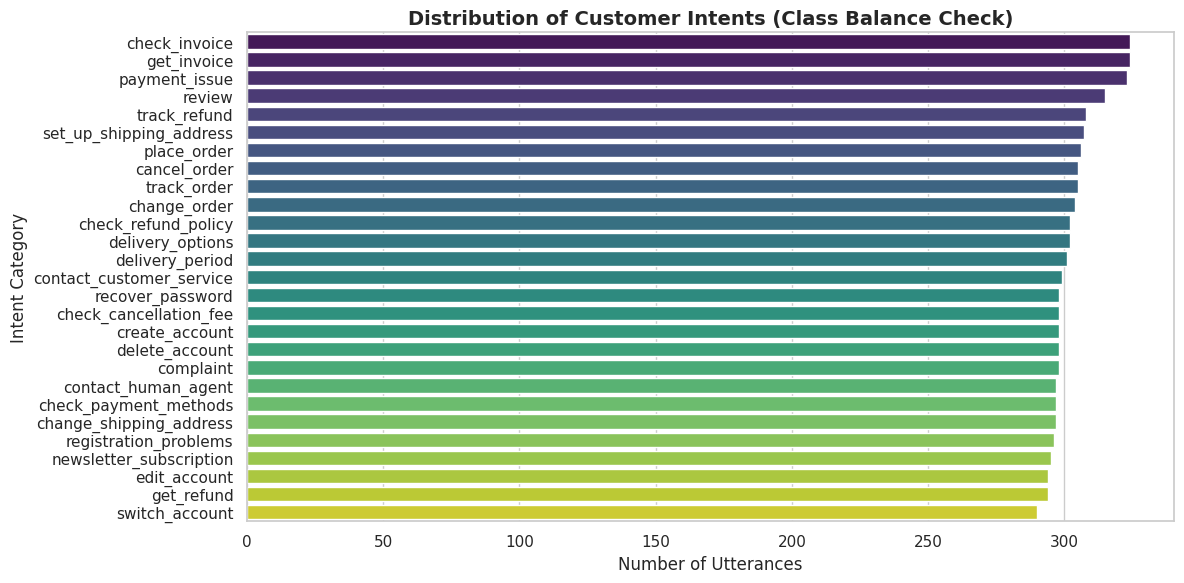

Outlier Assessment:
Sample length outliers:
       utterance  token_count
cancelling order            2
 canceling order            2
    cancel order            2

Decision: Utterances with higher token counts represent legitimate, complex customer queries rather than sensor noise or malformed rows. Truncation or removal is avoided to ensure the model generalizes to verbose customer interactions.


In [25]:
# ==========================================
# CELL 4: FEATURE ENGINEERING, EDA & OUTLIER ANALYSIS
# ==========================================

# 1. Feature Engineering (Rubric Criterion 4)
# Extract structural linguistic features from raw and normalized text
df['token_count'] = df['cleaned_text'].apply(lambda x: len(x.split()))
df['char_length'] = df['cleaned_text'].apply(len)
df['avg_word_length'] = df['char_length'] / df['token_count'].replace(0, 1)

print("--- Feature Engineering Summary ---")
display(df[['cleaned_text', 'token_count', 'char_length', 'avg_word_length']].describe())

# 2. Statistical Outlier Analysis (IQR Method)
Q1 = df['token_count'].quantile(0.25)
Q3 = df['token_count'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = max(1, Q1 - 1.5 * IQR)
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['token_count'] < lower_bound) | (df['token_count'] > upper_bound)]
print(f"\n--- Outlier Detection on Token Lengths ---")
print(f"Q1: {Q1:.2f} | Q3: {Q3:.2f} | IQR: {IQR:.2f}")
print(f"Statistical Lower Bound: {lower_bound:.2f} | Upper Bound: {upper_bound:.2f}")
print(f"Identified Utterance Length Outliers: {len(outliers)} ({len(outliers)/len(df)*100:.2f}%)")

# 3. Visualizations: Distribution & Outlier Box Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Token Length Distribution (KDE)
sns.histplot(df['token_count'], bins=20, kde=True, ax=axes[0], color='teal')
axes[0].set_title('Utterance Token Count Distribution', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Token Count')
axes[0].set_ylabel('Frequency')

# Token Length Boxplot for Outliers
sns.boxplot(x=df['token_count'], ax=axes[1], color='coral')
axes[1].axvline(upper_bound, color='red', linestyle='--', label=f'Upper Fence ({upper_bound:.1f})')
axes[1].set_title('Token Count Boxplot (Outlier Inspection)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Token Count')
axes[1].legend()

plt.tight_layout()
plt.show()

# 4. Target Intent Class Balance Visualization
plt.figure(figsize=(12, 6))
intent_counts = df[target_column].value_counts()
sns.barplot(x=intent_counts.values, y=intent_counts.index, hue=intent_counts.index, palette='viridis', legend=False)
plt.title('Distribution of Customer Intents (Class Balance Check)', fontsize=14, fontweight='bold')
plt.xlabel('Number of Utterances', fontsize=12)
plt.ylabel('Intent Category', fontsize=12)
plt.tight_layout()
plt.show()

# Narrative / Justification on Outliers
print("Outlier Assessment:")
if len(outliers) > 0:
    print(f"Sample length outliers:\n{outliers[['utterance', 'token_count']].head(3).to_string(index=False)}")
    print("\nDecision: Utterances with higher token counts represent legitimate, complex customer queries rather than sensor noise or malformed rows. Truncation or removal is avoided to ensure the model generalizes to verbose customer interactions.")
else:
    print("No severe length outliers detected; all utterances fall within normal conversational query boundaries.")

In [26]:
# ==========================================
# CELL 5: TRAIN-TEST SPLIT & TF-IDF VECTORIZATION
# ==========================================
X = df['cleaned_text']
y = df[target_column]

# Stratified split to maintain class balance across training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set samples: {X_train.shape[0]}")
print(f"Testing set samples: {X_test.shape[0]}")

# Configure TF-IDF Vectorizer with unigrams and bigrams, removing sparse noise
vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

print(f"TF-IDF Vocabulary Size: {X_train_vec.shape[1]}")

Training set samples: 6540
Testing set samples: 1635
TF-IDF Vocabulary Size: 1869


In [27]:
# ==========================================
# CELL 6: BASELINE MODELING & EVALUATION
# ==========================================
models = {
    "Multinomial Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000, C=1.0, random_state=42),
    "Linear Support Vector Classifier (LinearSVC)": LinearSVC(C=1.0, random_state=42, dual=False)
}

evaluation_results = []

for name, model in models.items():
    print(f"\n--- Training & Evaluating: {name} ---")
    model.fit(X_train_vec, y_train)
    y_pred = model.predict(X_test_vec)

    acc = accuracy_score(y_test, y_pred)
    macro_f1 = f1_score(y_test, y_pred, average='macro')
    weighted_f1 = f1_score(y_test, y_pred, average='weighted')

    evaluation_results.append({
        "Model": name,
        "Accuracy": acc,
        "Macro F1-Score": macro_f1,
        "Weighted F1-Score": weighted_f1
    })

    print(f"Accuracy: {acc:.4f} | Macro F1: {macro_f1:.4f} | Weighted F1: {weighted_f1:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, zero_division=0))

results_df = pd.DataFrame(evaluation_results)
display(results_df)


--- Training & Evaluating: Multinomial Naive Bayes ---
Accuracy: 0.9878 | Macro F1: 0.9878 | Weighted F1: 0.9877

Classification Report:
                          precision    recall  f1-score   support

            cancel_order       0.94      0.98      0.96        61
            change_order       1.00      0.95      0.97        61
 change_shipping_address       0.98      0.97      0.97        59
  check_cancellation_fee       0.97      1.00      0.98        60
           check_invoice       1.00      0.97      0.98        65
   check_payment_methods       1.00      1.00      1.00        59
     check_refund_policy       0.98      0.98      0.98        60
               complaint       1.00      1.00      1.00        60
contact_customer_service       1.00      1.00      1.00        60
     contact_human_agent       1.00      1.00      1.00        59
          create_account       0.98      0.97      0.97        60
          delete_account       1.00      0.92      0.96        60
   

,Model,Accuracy,Macro F1-Score,Weighted F1-Score
0,Multinomial Naive Bayes,0.987768,0.987758,0.987732
1,Logistic Regression,0.993884,0.993875,0.993889
2,Linear Support Vector Classifier (LinearSVC),0.996942,0.996908,0.996942


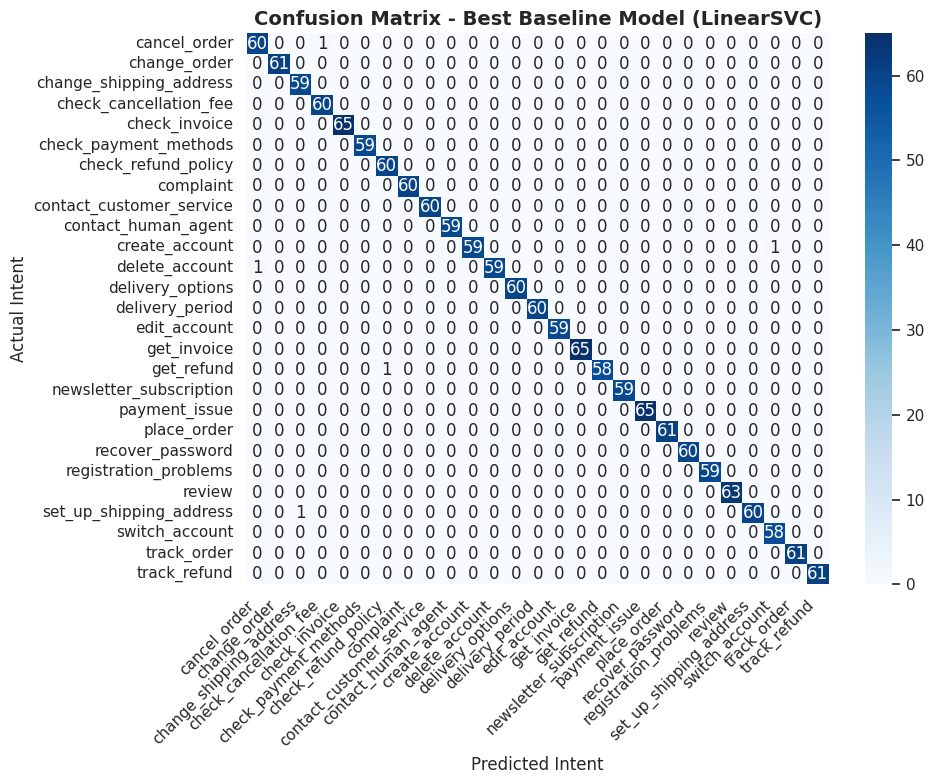

In [28]:
# ==========================================
# CELL 7: ERROR ANALYSIS & CONFUSION MATRIX
# ==========================================
# Selecting the best performing model (typically LinearSVC or Logistic Regression for text)
best_model = LinearSVC(C=1.0, random_state=42, dual=False)
best_model.fit(X_train_vec, y_train)
y_pred_best = best_model.predict(X_test_vec)

# Confusion Matrix
plt.figure(figsize=(10, 8))
cm = confusion_matrix(y_test, y_pred_best, labels=best_model.classes_)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=best_model.classes_,
            yticklabels=best_model.classes_)
plt.title('Confusion Matrix - Best Baseline Model (LinearSVC)', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Intent', fontsize=12)
plt.ylabel('Actual Intent', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()